In [42]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
POINT_VALUE = 20  # $ per point for NQ futures
STOP_DOLLARS = 2000
SLIPPAGE_PER_SIDE_TICKS = 1.5
SLIPPAGE_PER_TICK_VALUE = 5.0  # $ per tick for NQ (0.25 point * $20)
TARGET_DOLLARS = 4000
STOP_POINTS = STOP_DOLLARS / POINT_VALUE
TARGET_POINTS = TARGET_DOLLARS / POINT_VALUE
INITIAL_CAPITAL = 1_000_000
MARGIN_PER_CONTRACT = 23282.57 #IB NQ
MARGIN_BUFFER = 0.15
RISK_PCT = 0.01
FEE_PER_LEG = 0.85 # Interactive Brokers fee per leg for NQ futures
def position_size(equity, stop_pts, risk_pct=RISK_PCT, point_value=POINT_VALUE, margin=MARGIN_PER_CONTRACT, buffer=MARGIN_BUFFER):
    stop_pts = max(stop_pts, 1e-9)
    margin = max(margin, 1e-9)
    n_risk = (risk_pct * equity) / (stop_pts * point_value)
    n_margin = equity / (margin * (1 + buffer))
    n = min(n_risk, n_margin)
    return max(1, int(n))
TRADE_START = dt.time(10, 0)
TRADE_END = dt.time(14, 30)
REGULAR_START = dt.time(9, 30)
REGULAR_END = dt.time(16, 0)
WINDOW_START = dt.time(8, 30)
WINDOW_END = dt.time(10, 0)
MAX_TRADES_PER_DAY = 2
MAX_LONG_HOLD_DAYS = 5

In [43]:
from pathlib import Path

qqq_path = Path('Data/QQQ_daily.csv')
if not qqq_path.exists():
    raise FileNotFoundError('Data/QQQ_daily.csv non trovato: carica il file prima di proseguire.')

qqq = pd.read_csv(qqq_path)
if 'date' not in qqq.columns or 'close' not in qqq.columns:
    rename_map = {}
    for column in qqq.columns:
        lower = column.lower().strip()
        if lower == 'date':
            rename_map[column] = 'date'
        elif lower in {'close', 'adj close', 'adj_close'}:
            rename_map[column] = 'close'
    qqq = qqq.rename(columns=rename_map)
    if 'date' not in qqq.columns or 'close' not in qqq.columns:
        raise ValueError('QQQ_daily.csv deve contenere le colonne "date" e "close".')

qqq['date'] = pd.to_datetime(qqq['date'], errors='coerce')
qqq['close'] = pd.to_numeric(qqq['close'], errors='coerce')
qqq = qqq.dropna(subset=['date', 'close']).sort_values('date').reset_index(drop=True)

if qqq.empty:
    raise ValueError('QQQ_daily.csv non contiene righe valide dopo la pulizia.')


In [44]:
raw_df = pd.read_csv("Data/nq-10y-1min.csv")

raw_df['date'] = pd.to_datetime(raw_df['Date'] + ' ' + raw_df['Time'], format='%d/%m/%Y %H:%M:%S')
raw_df.rename(columns={"Open": "open", "High": "high", "Low": "low", "Close": "close", "TotalVolume": "totalvolume"}, inplace=True)

df_full = (raw_df.sort_values('date')
               .set_index('date')
               .resample('5min')
               .agg({
                   'open': 'first',
                   'high': 'max',
                   'low': 'min',
                   'close': 'last',
                   'totalvolume': 'sum'
               })
               .dropna(subset=['open', 'high', 'low', 'close'])
               .reset_index())

df_full['day'] = df_full['date'].dt.date
df_full['time'] = df_full['date'].dt.time

df_regular = df_full[(df_full['time'] >= REGULAR_START) & (df_full['time'] <= REGULAR_END)].copy()
daily_summary_regular = df_regular.groupby('day').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last'
})
daily_summary_regular['body'] = (daily_summary_regular['close'] - daily_summary_regular['open']).abs()
daily_summary_regular['range'] = daily_summary_regular['high'] - daily_summary_regular['low']

df = df_full[(df_full['time'] >= WINDOW_START) & (df_full['time'] <= TRADE_END)].copy()
df['running_high'] = df.groupby('day')['high'].cummax()
df['running_low'] = df.groupby('day')['low'].cummin()

day_to_index = {day: idx for idx, day in enumerate(daily_summary_regular.index)}


In [45]:

trades = []
open_trade = None
account_value = INITIAL_CAPITAL
current_day = None
prev_day = None
daily_trade_count = 0
window_high = None
window_low = None
window_ready = False
current_stats = {'open': None, 'high': None, 'low': None}
filters_today_pass = False
prev_row_timestamp = None
prev_row_close = None

def ensure_day_index(day):
    if day not in day_to_index:
        day_to_index[day] = len(day_to_index)
    return day_to_index[day]

def close_trade(exit_time, exit_price, exit_reason, exit_day):
    global open_trade, account_value
    entry_idx = ensure_day_index(open_trade['entry_day'])
    exit_idx = ensure_day_index(exit_day)
    days_in_trade = exit_idx - entry_idx + 1
    contracts = open_trade.get('contracts', 1)
    if open_trade['direction'] == 'long':
        pnl_per_contract = (exit_price - open_trade['entry_price']) * POINT_VALUE
    else:
        pnl_per_contract = (open_trade['entry_price'] - exit_price) * POINT_VALUE
    fee_per_contract = FEE_PER_LEG * 2
    slippage_per_contract = SLIPPAGE_PER_SIDE_TICKS * SLIPPAGE_PER_TICK_VALUE
    pnl_per_contract -= (fee_per_contract + slippage_per_contract)
    pnl = pnl_per_contract * contracts
    account_value += pnl
    trades.append({
        'direction': open_trade['direction'],
        'entry_time': open_trade['entry_time'],
        'exit_time': exit_time,
        'entry_price': open_trade['entry_price'],
        'exit_price': exit_price,
        'contracts': contracts,
        'stop_points': open_trade.get('stop_pts'),
        'pnl_per_contract': pnl_per_contract,
        'pnl': pnl,
        'fees': fee_per_contract * contracts,
        'exit_reason': exit_reason,
        'days_in_trade': days_in_trade,
        'account_value': account_value,
        'risk_points': open_trade.get('risk_points'),
        'risk_pct': open_trade.get('risk_pct'),
        'risk_dollars': open_trade.get('risk_dollars'),
        'account_value_entry': open_trade.get('account_value_entry'),
    })
    open_trade = None

for row in df.itertuples(index=False):
    row_timestamp = pd.Timestamp(row.date)
    row_day = row_timestamp.date()
    row_time = row_timestamp.time()
    ensure_day_index(row_day)

    if current_day is None:
        current_day = row_day
    if row_day != current_day:
        if open_trade is not None and open_trade['direction'] == 'short':
            close_trade(prev_row_timestamp, prev_row_close, 'eod_short', current_day)
        prev_day = current_day
        current_day = row_day
        daily_trade_count = 0
        window_high = None
        window_low = None
        window_ready = False
        current_stats = {'open': None, 'high': None, 'low': None}
        filters_today_pass = False

    if WINDOW_START <= row_time <= WINDOW_END:
        window_high = row.high if window_high is None else max(window_high, row.high)
        window_low = row.low if window_low is None else min(window_low, row.low)
    if not window_ready and row_time >= WINDOW_END and window_high is not None and window_low is not None:
        window_ready = True

    if REGULAR_START <= row_time <= REGULAR_END:
        if current_stats['open'] is None:
            current_stats['open'] = row.open
        current_stats['high'] = row.high if current_stats['high'] is None else max(current_stats['high'], row.high)
        current_stats['low'] = row.low if current_stats['low'] is None else min(current_stats['low'], row.low)

    if window_ready:
        prev_summary = daily_summary_regular.loc[prev_day] if prev_day in daily_summary_regular.index else None
        if prev_summary is not None and None not in (current_stats['open'], current_stats['high'], current_stats['low']):
            cond1 = True
            cond2 = True
            cond3 = True
            cond4 = True
            filters_today_pass = cond1 and cond2 and cond3 and cond4
        else:
            filters_today_pass = False

    if open_trade is not None:
        exit_price = None
        exit_reason = None
        entry_idx = ensure_day_index(open_trade['entry_day'])
        current_idx = ensure_day_index(row_day)
        days_in_trade = current_idx - entry_idx + 1
        if open_trade['direction'] == 'long':
            if row.low <= open_trade['stop']:
                exit_price = open_trade['stop']
                exit_reason = 'stop'
            elif row.high >= open_trade['target']:
                exit_price = open_trade['target']
                exit_reason = 'target'
            elif days_in_trade >= MAX_LONG_HOLD_DAYS:
                exit_price = row.close
                exit_reason = 'max_hold'
        else:
            if row.high >= open_trade['stop']:
                exit_price = open_trade['stop']
                exit_reason = 'stop'
            elif row.low <= open_trade['target']:
                exit_price = open_trade['target']
                exit_reason = 'target'
            elif row_time >= TRADE_END:
                exit_price = row.close
                exit_reason = 'eod_short'
        if exit_price is not None:
            close_trade(row_timestamp, exit_price, exit_reason, row_day)
            prev_row_timestamp = row_timestamp
            prev_row_close = row.close
            continue

    if (open_trade is None and window_ready and filters_today_pass
            and window_high is not None and window_low is not None
            and daily_trade_count < MAX_TRADES_PER_DAY
            and TRADE_START <= row_time <= TRADE_END):
        direction = None
        entry_price = None
        stop = None
        target = None
        if row.high > window_high:
            direction = 'long'
            entry_price = row.close
            stop = entry_price - STOP_POINTS
            target = entry_price + TARGET_POINTS
        elif row.low < window_low:
            direction = 'short'
            entry_price = row.close
            stop = entry_price + STOP_POINTS
            target = entry_price - TARGET_POINTS
        if direction is not None:
            stop_pts = abs(entry_price - stop)
            contracts = int(position_size(account_value, stop_pts))
            open_trade = {
                'direction': direction,
                'entry_time': row_timestamp,
                'entry_price': entry_price,
                'stop': stop,
                'target': target,
                'entry_day': row_day,
                'stop_pts': stop_pts,
                'contracts': contracts,
                'risk_per_contract': stop_pts * POINT_VALUE,
                'risk_dollars': stop_pts * POINT_VALUE * contracts,
                'risk_points': stop_pts * contracts,
                'account_value_entry': account_value,
                'risk_pct': (stop_pts * POINT_VALUE * contracts / account_value * 100) if account_value else float('nan')
            }
            daily_trade_count += 1

    prev_row_timestamp = row_timestamp
    prev_row_close = row.close

if open_trade is not None:
    last_timestamp = pd.Timestamp(df.iloc[-1]['date'])
    last_day = last_timestamp.date()
    ensure_day_index(last_day)
    close_trade(last_timestamp, df.iloc[-1]['close'], 'force_close', last_day)

              entry_time           exit_time direction  contracts      pnl  \
1723 2025-04-02 12:15:00 2025-04-02 12:45:00      long         22 -44202.4   
1724 2025-04-03 10:05:00 2025-04-03 10:15:00     short         21 -42193.2   
1725 2025-04-03 13:30:00 2025-04-03 14:30:00     short         21  31096.8   
1726 2025-04-04 12:15:00 2025-04-04 12:25:00     short         21 -42193.2   
1727 2025-04-04 13:25:00 2025-04-04 14:25:00     short         21 -42193.2   

      days_in_trade exit_reason  
1723              1        stop  
1724              1        stop  
1725              1   eod_short  
1726              1        stop  
1727              1        stop  
------------------------------------------------------------------------------------------------------------------------
Total trades: 1728, Net PnL: 3287392.20
Average trade PnL: 1902.43 | Avg contracts: 9.37 | Avg PnL/contract: 191.33
Last trade unit PnL: -2009.20 | Prev: -2009.20 | Diff: 0.00


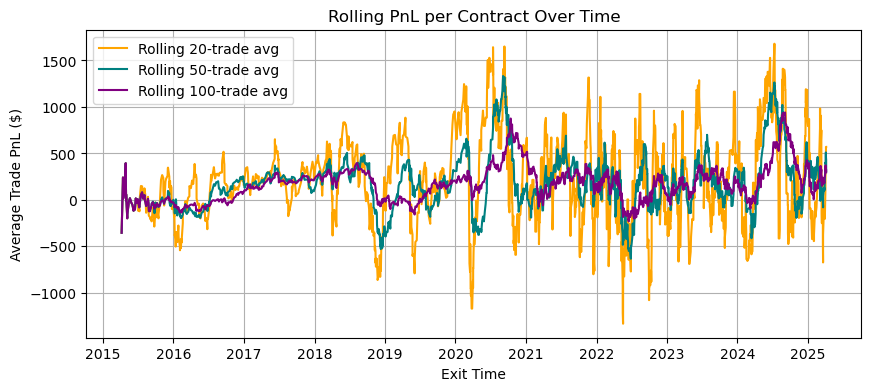

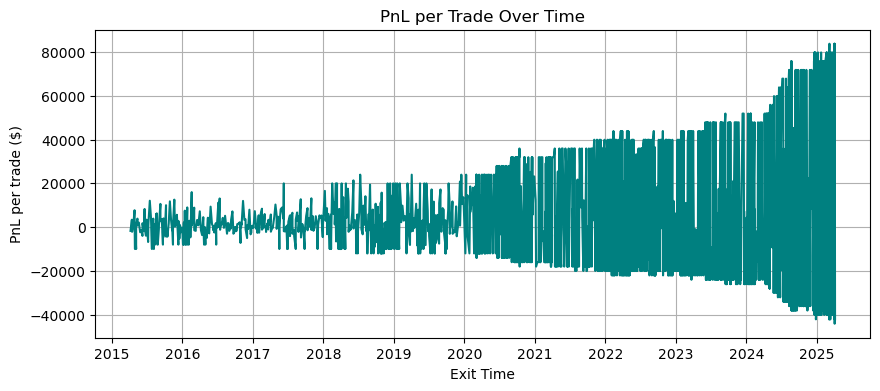

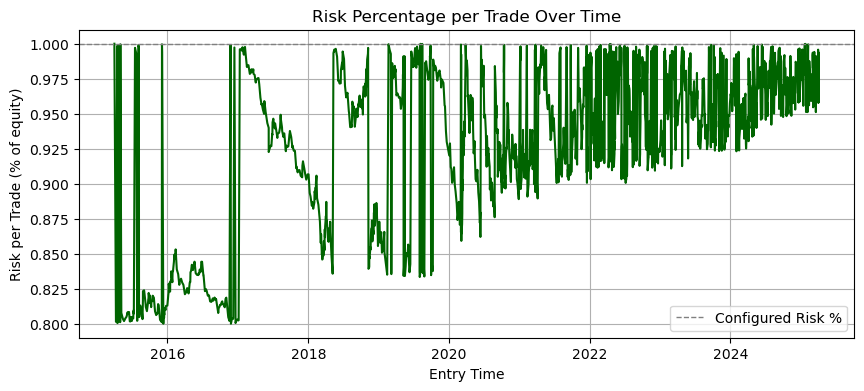

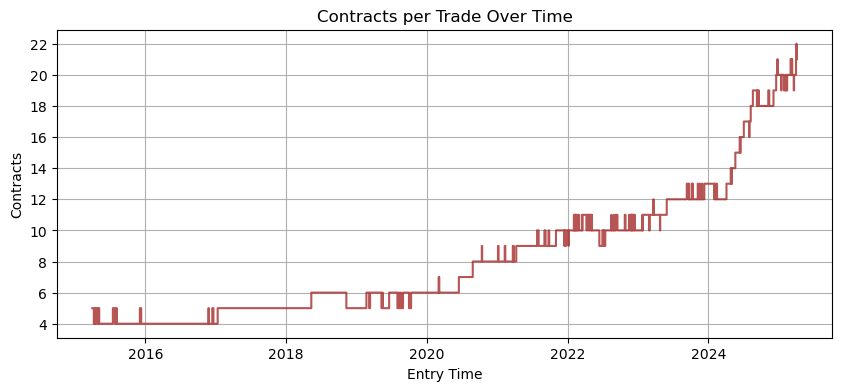

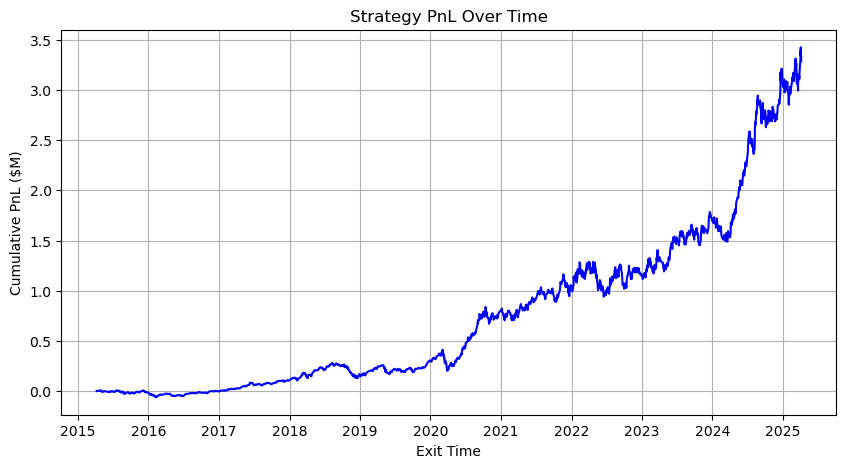

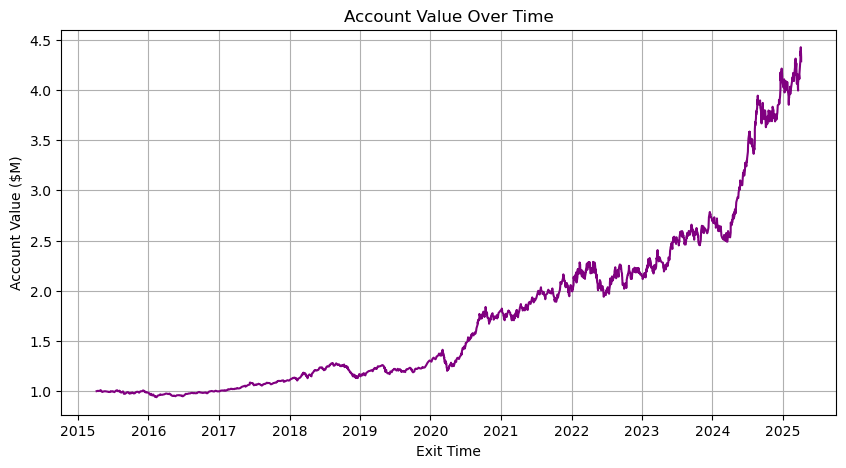

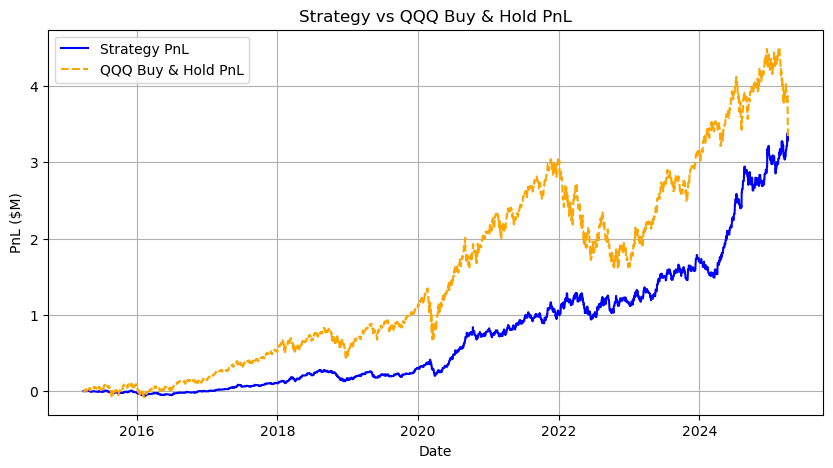

In [46]:
trades_df = pd.DataFrame(trades)

if trades_df.empty:
    print('No trades generated.')
else:
    trades_df['cumulative_pnl'] = trades_df['pnl'].cumsum()
    trades_df['account_value'] = INITIAL_CAPITAL + trades_df['cumulative_pnl']
    trades_df['contracts'] = trades_df['contracts'].round().astype(int)

    print(trades_df[['entry_time', 'exit_time', 'direction', 'contracts', 'pnl', 'days_in_trade', 'exit_reason']].tail())
    print("-" * 120)
    print(f"Total trades: {len(trades_df)}, Net PnL: {trades_df['pnl'].sum():.2f}")
    avg_pnl = trades_df['pnl'].mean()
    avg_contracts = trades_df['contracts'].mean() if 'contracts' in trades_df else float('nan')
    avg_pnl_per_contract = trades_df['pnl_per_contract'].mean() if 'pnl_per_contract' in trades_df else float('nan')
    print(f"Average trade PnL: {avg_pnl:.2f} | Avg contracts: {avg_contracts:.2f} | Avg PnL/contract: {avg_pnl_per_contract:.2f}")

    if 'pnl_per_contract' in trades_df and len(trades_df) >= 2:
        sorted_units = trades_df.sort_values('exit_time')['pnl_per_contract'].reset_index(drop=True)
        unit_diffs = sorted_units.diff()
        print(f"Last trade unit PnL: {sorted_units.iloc[-1]:.2f} | Prev: {sorted_units.iloc[-2]:.2f} | Diff: {unit_diffs.iloc[-1]:.2f}")

    strategy_start_date = pd.to_datetime(trades_df['entry_time']).min().normalize()
    strategy_end_date = pd.to_datetime(trades_df['exit_time']).max().normalize()
    all_dates = pd.date_range(start=strategy_start_date, end=strategy_end_date, freq='D')

    strategy_dates = pd.to_datetime(trades_df['exit_time']).dt.normalize()
    strategy_daily = (pd.DataFrame({'date': strategy_dates, 'account_value': trades_df['account_value']})
                      .groupby('date')['account_value'].last()
                      .reindex(all_dates)
                      .ffill()
                      .fillna(INITIAL_CAPITAL))

    qqq_slice = qqq[(qqq['date'] <= strategy_end_date)].copy()
    if qqq_slice.empty:
        raise ValueError('QQQ data does not include the strategy period.')
    qqq_slice = qqq_slice.set_index('date')
    qqq_aligned = qqq_slice.reindex(all_dates).ffill().bfill()
    if qqq_aligned['close'].isna().any():
        raise ValueError('QQQ data has gaps even after interpolation.')

    shares = INITIAL_CAPITAL / qqq_aligned['close'].iloc[0]
    qqq_pnl = (qqq_aligned['close'] - qqq_aligned['close'].iloc[0]) * shares
    qqq_account = shares * qqq_aligned['close']
    strategy_pnl = strategy_daily - INITIAL_CAPITAL

    sorted_trades = trades_df.sort_values('exit_time').reset_index(drop=True)
    sorted_trades['exit_time'] = pd.to_datetime(sorted_trades['exit_time'])

    avg_pnl_over_time = sorted_trades[['exit_time', 'pnl']].copy()
    avg_pnl_over_time['avg_pnl'] = avg_pnl_over_time['pnl'].expanding().mean()
    if 'pnl_per_contract' in sorted_trades:
        avg_pnl_over_time['avg_pnl_per_contract'] = sorted_trades['pnl_per_contract'].expanding().mean()
    else:
        avg_pnl_over_time['avg_pnl_per_contract'] = (
            avg_pnl_over_time['avg_pnl'] / avg_contracts if avg_contracts else avg_pnl_over_time['avg_pnl']
        )

    if 'pnl_per_contract' in sorted_trades and len(sorted_trades) >= 2:
        unit_diff_over_time = sorted_trades[['exit_time', 'pnl_per_contract']].copy()
        unit_diff_over_time['unit_diff'] = unit_diff_over_time['pnl_per_contract'].diff()
        unit_diff_over_time = unit_diff_over_time.dropna()
    else:
        unit_diff_over_time = pd.DataFrame(columns=['exit_time', 'unit_diff'])


    plt.figure(figsize=(10, 4))
    if 'pnl_per_contract' in sorted_trades:
        for window, color in [(20, 'orange'), (50, 'teal'), (100, 'purple')]:
            rolling_avg = sorted_trades['pnl_per_contract'].rolling(window=window, min_periods=1).mean()
            plt.plot(sorted_trades['exit_time'], rolling_avg, label=f'Rolling {window}-trade avg', color=color)
    plt.xlabel('Exit Time')
    plt.ylabel('Average Trade PnL ($)')
    plt.title('Rolling PnL per Contract Over Time')
    plt.legend(loc='upper left')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(sorted_trades['exit_time'], sorted_trades['pnl'], color='teal')
    plt.xlabel('Exit Time')
    plt.ylabel('PnL per trade ($)')
    plt.title('PnL per Trade Over Time')
    plt.grid()
    plt.show()

    if {'risk_dollars', 'account_value_entry'}.issubset(trades_df.columns):
        risk_series = trades_df.sort_values('entry_time').copy()
        risk_series['entry_time'] = pd.to_datetime(risk_series['entry_time'])
        risk_series['risk_dollars'] = pd.to_numeric(risk_series['risk_dollars'], errors='coerce')
        risk_series['account_value_entry'] = pd.to_numeric(risk_series['account_value_entry'], errors='coerce')
        risk_series = risk_series.dropna(subset=['risk_dollars', 'account_value_entry'])
        risk_series = risk_series[risk_series['account_value_entry'] != 0]
        if not risk_series.empty:
            risk_series['risk_pct_calc'] = risk_series['risk_dollars'] / risk_series['account_value_entry'] * 100
            plt.figure(figsize=(10, 4))
            plt.plot(risk_series['entry_time'], risk_series['risk_pct_calc'], color='darkgreen')
            plt.axhline(RISK_PCT * 100, color='gray', linestyle='--', linewidth=1, label='Configured Risk %')
            plt.xlabel('Entry Time')
            plt.ylabel('Risk per Trade (% of equity)')
            plt.title('Risk Percentage per Trade Over Time')
            plt.legend()
            plt.grid()
            plt.show()

    contracts_timeline = trades_df[['entry_time', 'contracts']].copy()
    contracts_timeline['entry_time'] = pd.to_datetime(contracts_timeline['entry_time'])
    contracts_timeline = contracts_timeline.sort_values('entry_time').reset_index(drop=True)

    plt.figure(figsize=(10, 4))
    ax = plt.gca()
    ax.step(contracts_timeline['entry_time'], contracts_timeline['contracts'], where='post', color='brown', alpha=0.8)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    plt.xlabel('Entry Time')
    plt.ylabel('Contracts')
    plt.title('Contracts per Trade Over Time')
    plt.grid()
    plt.show()


    plt.figure(figsize=(10, 5))
    plt.plot(trades_df['exit_time'], trades_df['cumulative_pnl'] / 1e6, color='blue')
    plt.xlabel('Exit Time')
    plt.ylabel('Cumulative PnL ($M)')
    plt.title('Strategy PnL Over Time')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(trades_df['exit_time'], trades_df['account_value'] / 1e6, color='purple')
    plt.xlabel('Exit Time')
    plt.ylabel('Account Value ($M)')
    plt.title('Account Value Over Time')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(strategy_daily.index, strategy_pnl / 1e6, label='Strategy PnL', color='blue')
    plt.plot(qqq_aligned.index, qqq_pnl / 1e6, label='QQQ Buy & Hold PnL', color='orange', linestyle='dashed')
    plt.xlabel('Date')
    plt.ylabel('PnL ($M)')
    plt.title('Strategy vs QQQ Buy & Hold PnL')
    plt.legend()
    plt.grid()
    plt.show()

    strategy_daily_equity = strategy_daily
    qqq_daily_equity = qqq_account

In [47]:
import numpy as np
import pandas as pd

if 'strategy_daily_equity' not in locals() or 'qqq_daily_equity' not in locals():
    raise RuntimeError('Run the plotting cell to build aligned equity curves before computing metrics.')

def compute_metrics(equity_series, freq=252):
    returns = equity_series.pct_change().dropna()
    if returns.empty:
        return {
            'Sharpe': np.nan,
            'Volatility': np.nan,
            'Max Drawdown %': np.nan,
            'Max Drawdown $': np.nan,
            'CAGR': np.nan
        }
    avg_ret = returns.mean()
    std_ret = returns.std(ddof=1)
    vol = std_ret * np.sqrt(freq)
    sharpe = avg_ret / std_ret * np.sqrt(freq) if std_ret > 0 else np.nan
    running_max = equity_series.cummax()
    drawdown_abs = equity_series - running_max
    drawdown_pct = drawdown_abs / running_max
    max_dd_abs = drawdown_abs.min()
    max_dd_pct = drawdown_pct.min()
    total_years = (equity_series.index[-1] - equity_series.index[0]).days / 365.25
    cagr = (equity_series.iloc[-1] / equity_series.iloc[0]) ** (1 / total_years) - 1 if total_years > 0 else np.nan
    return {
        'Sharpe': sharpe,
        'Volatility': vol,
        'Max Drawdown %': max_dd_pct,
        'Max Drawdown $': max_dd_abs,
        'CAGR': cagr
    }

def compute_segment_metrics(strategy_eq, benchmark_eq, freq=252):
    data = [
        compute_metrics(strategy_eq, freq),
        compute_metrics(benchmark_eq, freq)
    ]
    return pd.DataFrame(data, index=['NQ Strategy', 'QQQ Buy & Hold'])

def format_metrics(df):
    formatted = df.copy()
    if 'Sharpe' in formatted.columns:
        formatted['Sharpe'] = formatted['Sharpe'].map(lambda x: f"{x:.2f}" if pd.notnull(x) else '—')
    if 'Volatility' in formatted.columns:
        formatted['Volatility'] = formatted['Volatility'].map(lambda x: f"{x:.2%}" if pd.notnull(x) else '—')
    if 'Max Drawdown %' in formatted.columns:
        formatted['Max Drawdown %'] = formatted['Max Drawdown %'].map(lambda x: f"{abs(x):.2%}" if pd.notnull(x) else '—')
    if 'Max Drawdown $' in formatted.columns:
        formatted['Max Drawdown $'] = formatted['Max Drawdown $'].map(lambda x: f"{x:,.0f}" if pd.notnull(x) else '—')
    if 'CAGR' in formatted.columns:
        formatted['CAGR'] = formatted['CAGR'].map(lambda x: f"{x:.2%}" if pd.notnull(x) else '—')
    return formatted

overall_df = compute_segment_metrics(strategy_daily_equity, qqq_daily_equity)
print('Overall metrics:')
display(format_metrics(overall_df))

split_date = pd.Timestamp('2022-01-31')
strategy_in_sample = strategy_daily_equity[strategy_daily_equity.index < split_date]
strategy_oos = strategy_daily_equity[strategy_daily_equity.index >= split_date]
benchmark_in_sample = qqq_daily_equity[qqq_daily_equity.index < split_date]
benchmark_oos = qqq_daily_equity[qqq_daily_equity.index >= split_date]

print('In-Sample metrics (before {}):'.format(split_date.date()))
display(format_metrics(compute_segment_metrics(strategy_in_sample, benchmark_in_sample)))

print('Out-of-Sample metrics (from {} onwards):'.format(split_date.date()))
display(format_metrics(compute_segment_metrics(strategy_oos, benchmark_oos)))

Overall metrics:


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ Strategy,0.95,11.25%,15.06%,"-361,027",15.65%
QQQ Buy & Hold,0.64,18.36%,35.12%,"-1,417,742",15.74%


In-Sample metrics (before 2022-01-31):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ Strategy,0.90,8.69%,14.88%,"-218,605",11.43%
QQQ Buy & Hold,0.81,17.63%,28.56%,"-670,105",20.21%


Out-of-Sample metrics (from 2022-01-31 onwards):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ Strategy,1.06,15.34%,15.06%,"-361,027",24.57%
QQQ Buy & Hold,0.29,19.79%,29.56%,"-1,186,501",5.63%


In [48]:
RISK_PCT = 0.02

def position_size(equity, stop_pts, risk_pct=RISK_PCT, point_value=POINT_VALUE, margin=MARGIN_PER_CONTRACT, buffer=MARGIN_BUFFER):
    stop_pts = max(stop_pts, 1e-9)
    margin = max(margin, 1e-9)
    n_risk = (risk_pct * equity) / (stop_pts * point_value)
    n_margin = equity / (margin * (1 + buffer))
    n = min(n_risk, n_margin)
    return max(1, int(n))

trades = []
open_trade = None
account_value = INITIAL_CAPITAL
current_day = None
prev_day = None
daily_trade_count = 0
window_high = None
window_low = None
window_ready = False
current_stats = {'open': None, 'high': None, 'low': None}
filters_today_pass = False
prev_row_timestamp = None
prev_row_close = None

def ensure_day_index(day):
    if day not in day_to_index:
        day_to_index[day] = len(day_to_index)
    return day_to_index[day]

def close_trade(exit_time, exit_price, exit_reason, exit_day):
    global open_trade, account_value
    entry_idx = ensure_day_index(open_trade['entry_day'])
    exit_idx = ensure_day_index(exit_day)
    days_in_trade = exit_idx - entry_idx + 1
    contracts = open_trade.get('contracts', 1)
    if open_trade['direction'] == 'long':
        pnl_per_contract = (exit_price - open_trade['entry_price']) * POINT_VALUE
    else:
        pnl_per_contract = (open_trade['entry_price'] - exit_price) * POINT_VALUE
    fee_per_contract = FEE_PER_LEG * 2
    slippage_per_contract = SLIPPAGE_PER_SIDE_TICKS * SLIPPAGE_PER_TICK_VALUE
    pnl_per_contract -= (fee_per_contract + slippage_per_contract)
    pnl = pnl_per_contract * contracts
    account_value += pnl
    trades.append({
        'direction': open_trade['direction'],
        'entry_time': open_trade['entry_time'],
        'exit_time': exit_time,
        'entry_price': open_trade['entry_price'],
        'exit_price': exit_price,
        'contracts': contracts,
        'stop_points': open_trade.get('stop_pts'),
        'pnl_per_contract': pnl_per_contract,
        'pnl': pnl,
        'fees': fee_per_contract * contracts,
        'exit_reason': exit_reason,
        'days_in_trade': days_in_trade,
        'account_value': account_value,
        'risk_points': open_trade.get('risk_points'),
        'risk_pct': open_trade.get('risk_pct'),
        'risk_dollars': open_trade.get('risk_dollars'),
        'account_value_entry': open_trade.get('account_value_entry'),
    })
    open_trade = None

for row in df.itertuples(index=False):
    row_timestamp = pd.Timestamp(row.date)
    row_day = row_timestamp.date()
    row_time = row_timestamp.time()
    ensure_day_index(row_day)

    if current_day is None:
        current_day = row_day
    if row_day != current_day:
        if open_trade is not None and open_trade['direction'] == 'short':
            close_trade(prev_row_timestamp, prev_row_close, 'eod_short', current_day)
        prev_day = current_day
        current_day = row_day
        daily_trade_count = 0
        window_high = None
        window_low = None
        window_ready = False
        current_stats = {'open': None, 'high': None, 'low': None}
        filters_today_pass = False

    if WINDOW_START <= row_time <= WINDOW_END:
        window_high = row.high if window_high is None else max(window_high, row.high)
        window_low = row.low if window_low is None else min(window_low, row.low)
    if not window_ready and row_time >= WINDOW_END and window_high is not None and window_low is not None:
        window_ready = True

    if REGULAR_START <= row_time <= REGULAR_END:
        if current_stats['open'] is None:
            current_stats['open'] = row.open
        current_stats['high'] = row.high if current_stats['high'] is None else max(current_stats['high'], row.high)
        current_stats['low'] = row.low if current_stats['low'] is None else min(current_stats['low'], row.low)

    if window_ready:
        prev_summary = daily_summary_regular.loc[prev_day] if prev_day in daily_summary_regular.index else None
        if prev_summary is not None and None not in (current_stats['open'], current_stats['high'], current_stats['low']):
            cond1 = True
            cond2 = True
            cond3 = True
            cond4 = True
            filters_today_pass = cond1 and cond2 and cond3 and cond4
        else:
            filters_today_pass = False

    if open_trade is not None:
        exit_price = None
        exit_reason = None
        entry_idx = ensure_day_index(open_trade['entry_day'])
        current_idx = ensure_day_index(row_day)
        days_in_trade = current_idx - entry_idx + 1
        if open_trade['direction'] == 'long':
            if row.low <= open_trade['stop']:
                exit_price = open_trade['stop']
                exit_reason = 'stop'
            elif row.high >= open_trade['target']:
                exit_price = open_trade['target']
                exit_reason = 'target'
            elif days_in_trade >= MAX_LONG_HOLD_DAYS:
                exit_price = row.close
                exit_reason = 'max_hold'
        else:
            if row.high >= open_trade['stop']:
                exit_price = open_trade['stop']
                exit_reason = 'stop'
            elif row.low <= open_trade['target']:
                exit_price = open_trade['target']
                exit_reason = 'target'
            elif row_time >= TRADE_END:
                exit_price = row.close
                exit_reason = 'eod_short'
        if exit_price is not None:
            close_trade(row_timestamp, exit_price, exit_reason, row_day)
            prev_row_timestamp = row_timestamp
            prev_row_close = row.close
            continue

    if (open_trade is None and window_ready and filters_today_pass
            and window_high is not None and window_low is not None
            and daily_trade_count < MAX_TRADES_PER_DAY
            and TRADE_START <= row_time <= TRADE_END):
        direction = None
        entry_price = None
        stop = None
        target = None
        if row.high > window_high:
            direction = 'long'
            entry_price = row.close
            stop = entry_price - STOP_POINTS
            target = entry_price + TARGET_POINTS
        elif row.low < window_low:
            direction = 'short'
            entry_price = row.close
            stop = entry_price + STOP_POINTS
            target = entry_price - TARGET_POINTS
        if direction is not None:
            stop_pts = abs(entry_price - stop)
            contracts = int(position_size(account_value, stop_pts))
            open_trade = {
                'direction': direction,
                'entry_time': row_timestamp,
                'entry_price': entry_price,
                'stop': stop,
                'target': target,
                'entry_day': row_day,
                'stop_pts': stop_pts,
                'contracts': contracts,
                'risk_per_contract': stop_pts * POINT_VALUE,
                'risk_dollars': stop_pts * POINT_VALUE * contracts,
                'risk_points': stop_pts * contracts,
                'account_value_entry': account_value,
                'risk_pct': (stop_pts * POINT_VALUE * contracts / account_value * 100) if account_value else float('nan')
            }
            daily_trade_count += 1

    prev_row_timestamp = row_timestamp
    prev_row_close = row.close

if open_trade is not None:
    last_timestamp = pd.Timestamp(df.iloc[-1]['date'])
    last_day = last_timestamp.date()
    ensure_day_index(last_day)
    close_trade(last_timestamp, df.iloc[-1]['close'], 'force_close', last_day)

              entry_time           exit_time direction  contracts       pnl  \
1723 2025-04-02 12:15:00 2025-04-02 12:45:00      long        185 -371702.0   
1724 2025-04-03 10:05:00 2025-04-03 10:15:00     short        181 -363665.2   
1725 2025-04-03 13:30:00 2025-04-03 14:30:00     short        178  263582.4   
1726 2025-04-04 12:15:00 2025-04-04 12:25:00     short        180 -361656.0   
1727 2025-04-04 13:25:00 2025-04-04 14:25:00     short        177 -355628.4   

      days_in_trade exit_reason  
1723              1        stop  
1724              1        stop  
1725              1   eod_short  
1726              1        stop  
1727              1        stop  
------------------------------------------------------------------------------------------------------------------------
Total trades: 1728, Net PnL: 16358914.00
Average trade PnL: 9466.96 | Avg contracts: 45.58 | Avg PnL/contract: 191.33
Last trade unit PnL: -2009.20 | Prev: -2009.20 | Diff: 0.00


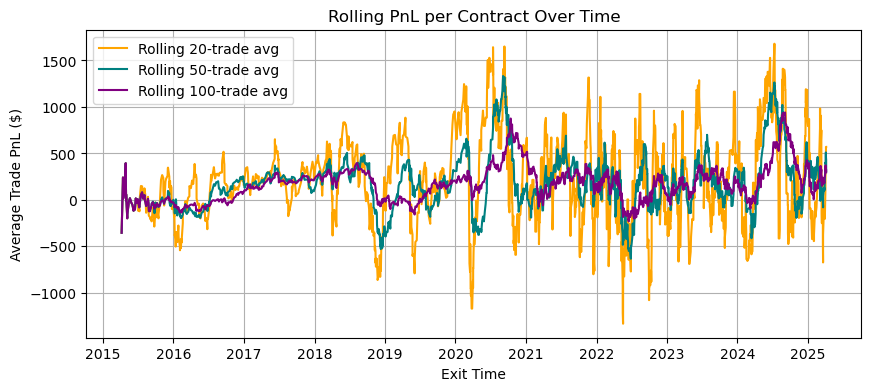

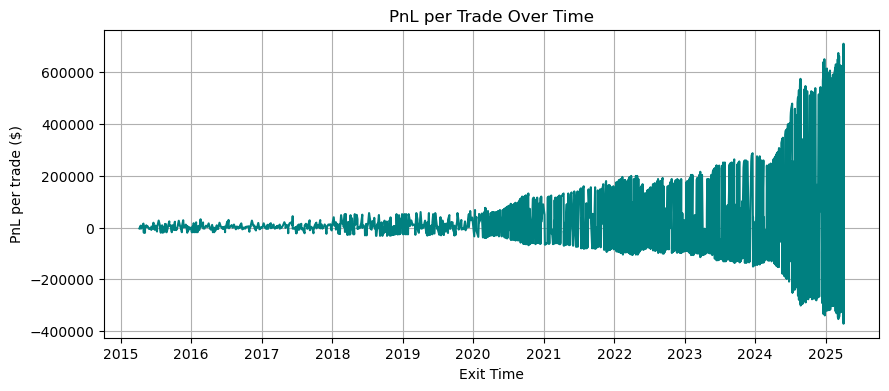

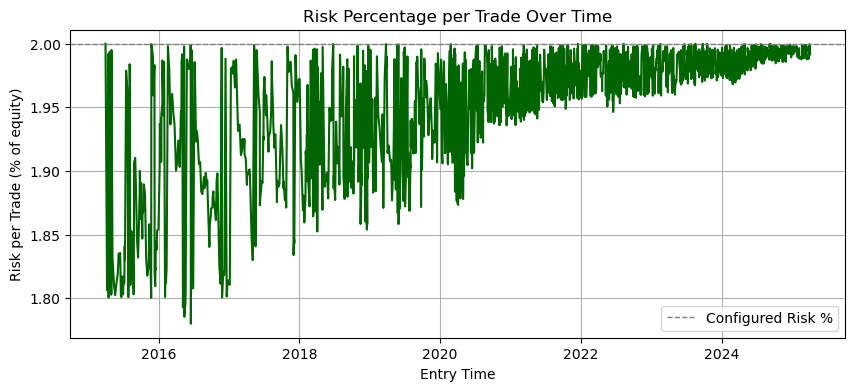

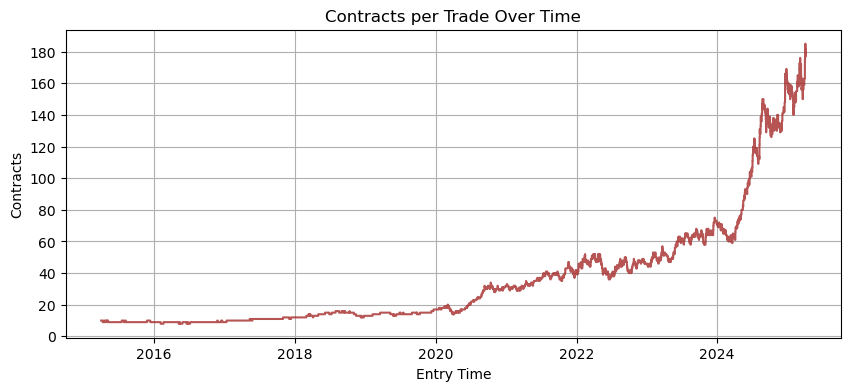

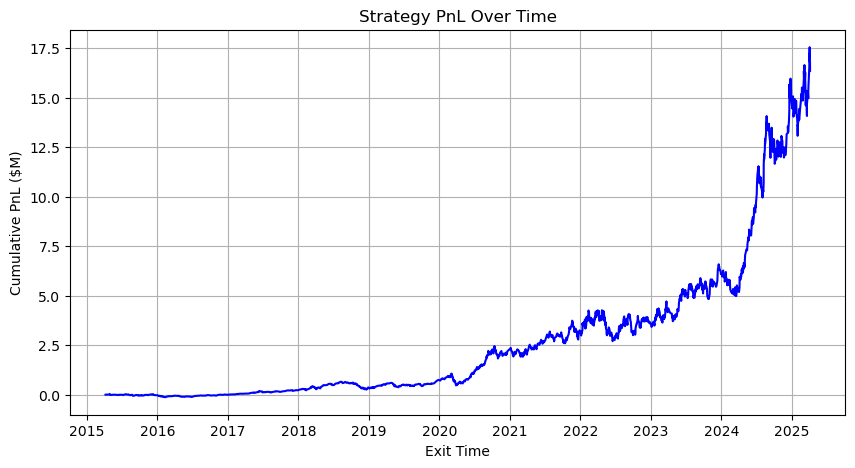

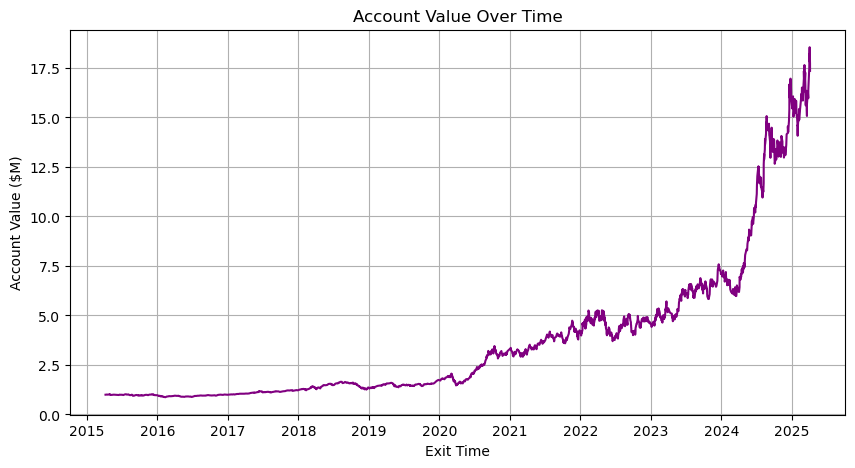

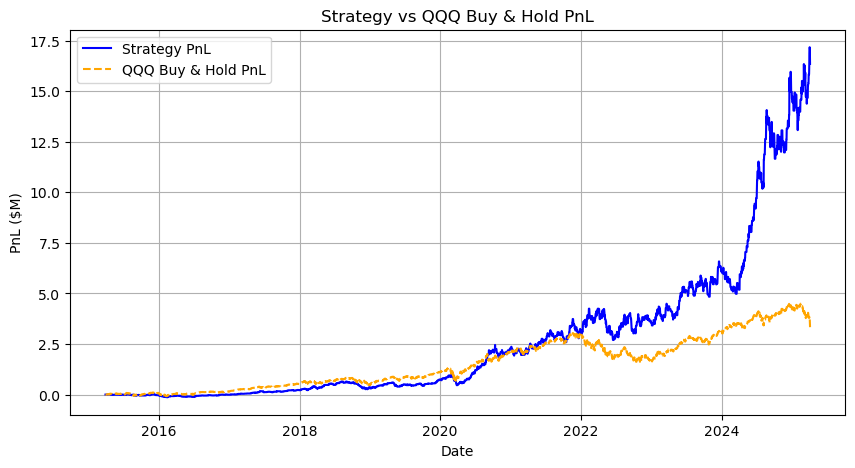

In [49]:
trades_df = pd.DataFrame(trades)

if trades_df.empty:
    print('No trades generated.')
else:
    trades_df['cumulative_pnl'] = trades_df['pnl'].cumsum()
    trades_df['account_value'] = INITIAL_CAPITAL + trades_df['cumulative_pnl']
    trades_df['contracts'] = trades_df['contracts'].round().astype(int)

    print(trades_df[['entry_time', 'exit_time', 'direction', 'contracts', 'pnl', 'days_in_trade', 'exit_reason']].tail())
    print("-" * 120)
    print(f"Total trades: {len(trades_df)}, Net PnL: {trades_df['pnl'].sum():.2f}")
    avg_pnl = trades_df['pnl'].mean()
    avg_contracts = trades_df['contracts'].mean() if 'contracts' in trades_df else float('nan')
    avg_pnl_per_contract = trades_df['pnl_per_contract'].mean() if 'pnl_per_contract' in trades_df else float('nan')
    print(f"Average trade PnL: {avg_pnl:.2f} | Avg contracts: {avg_contracts:.2f} | Avg PnL/contract: {avg_pnl_per_contract:.2f}")

    if 'pnl_per_contract' in trades_df and len(trades_df) >= 2:
        sorted_units = trades_df.sort_values('exit_time')['pnl_per_contract'].reset_index(drop=True)
        unit_diffs = sorted_units.diff()
        print(f"Last trade unit PnL: {sorted_units.iloc[-1]:.2f} | Prev: {sorted_units.iloc[-2]:.2f} | Diff: {unit_diffs.iloc[-1]:.2f}")

    strategy_start_date = pd.to_datetime(trades_df['entry_time']).min().normalize()
    strategy_end_date = pd.to_datetime(trades_df['exit_time']).max().normalize()
    all_dates = pd.date_range(start=strategy_start_date, end=strategy_end_date, freq='D')

    strategy_dates = pd.to_datetime(trades_df['exit_time']).dt.normalize()
    strategy_daily = (pd.DataFrame({'date': strategy_dates, 'account_value': trades_df['account_value']})
                      .groupby('date')['account_value'].last()
                      .reindex(all_dates)
                      .ffill()
                      .fillna(INITIAL_CAPITAL))

    qqq_slice = qqq[(qqq['date'] <= strategy_end_date)].copy()
    if qqq_slice.empty:
        raise ValueError('QQQ data does not include the strategy period.')
    qqq_slice = qqq_slice.set_index('date')
    qqq_aligned = qqq_slice.reindex(all_dates).ffill().bfill()
    if qqq_aligned['close'].isna().any():
        raise ValueError('QQQ data has gaps even after interpolation.')

    shares = INITIAL_CAPITAL / qqq_aligned['close'].iloc[0]
    qqq_pnl = (qqq_aligned['close'] - qqq_aligned['close'].iloc[0]) * shares
    qqq_account = shares * qqq_aligned['close']
    strategy_pnl = strategy_daily - INITIAL_CAPITAL

    sorted_trades = trades_df.sort_values('exit_time').reset_index(drop=True)
    sorted_trades['exit_time'] = pd.to_datetime(sorted_trades['exit_time'])

    avg_pnl_over_time = sorted_trades[['exit_time', 'pnl']].copy()
    avg_pnl_over_time['avg_pnl'] = avg_pnl_over_time['pnl'].expanding().mean()
    if 'pnl_per_contract' in sorted_trades:
        avg_pnl_over_time['avg_pnl_per_contract'] = sorted_trades['pnl_per_contract'].expanding().mean()
    else:
        avg_pnl_over_time['avg_pnl_per_contract'] = (
            avg_pnl_over_time['avg_pnl'] / avg_contracts if avg_contracts else avg_pnl_over_time['avg_pnl']
        )

    if 'pnl_per_contract' in sorted_trades and len(sorted_trades) >= 2:
        unit_diff_over_time = sorted_trades[['exit_time', 'pnl_per_contract']].copy()
        unit_diff_over_time['unit_diff'] = unit_diff_over_time['pnl_per_contract'].diff()
        unit_diff_over_time = unit_diff_over_time.dropna()
    else:
        unit_diff_over_time = pd.DataFrame(columns=['exit_time', 'unit_diff'])


    plt.figure(figsize=(10, 4))
    if 'pnl_per_contract' in sorted_trades:
        for window, color in [(20, 'orange'), (50, 'teal'), (100, 'purple')]:
            rolling_avg = sorted_trades['pnl_per_contract'].rolling(window=window, min_periods=1).mean()
            plt.plot(sorted_trades['exit_time'], rolling_avg, label=f'Rolling {window}-trade avg', color=color)
    plt.xlabel('Exit Time')
    plt.ylabel('Average Trade PnL ($)')
    plt.title('Rolling PnL per Contract Over Time')
    plt.legend(loc='upper left')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 4))
    plt.plot(sorted_trades['exit_time'], sorted_trades['pnl'], color='teal')
    plt.xlabel('Exit Time')
    plt.ylabel('PnL per trade ($)')
    plt.title('PnL per Trade Over Time')
    plt.grid()
    plt.show()

    if {'risk_dollars', 'account_value_entry'}.issubset(trades_df.columns):
        risk_series = trades_df.sort_values('entry_time').copy()
        risk_series['entry_time'] = pd.to_datetime(risk_series['entry_time'])
        risk_series['risk_dollars'] = pd.to_numeric(risk_series['risk_dollars'], errors='coerce')
        risk_series['account_value_entry'] = pd.to_numeric(risk_series['account_value_entry'], errors='coerce')
        risk_series = risk_series.dropna(subset=['risk_dollars', 'account_value_entry'])
        risk_series = risk_series[risk_series['account_value_entry'] != 0]
        if not risk_series.empty:
            risk_series['risk_pct_calc'] = risk_series['risk_dollars'] / risk_series['account_value_entry'] * 100
            plt.figure(figsize=(10, 4))
            plt.plot(risk_series['entry_time'], risk_series['risk_pct_calc'], color='darkgreen')
            plt.axhline(RISK_PCT * 100, color='gray', linestyle='--', linewidth=1, label='Configured Risk %')
            plt.xlabel('Entry Time')
            plt.ylabel('Risk per Trade (% of equity)')
            plt.title('Risk Percentage per Trade Over Time')
            plt.legend()
            plt.grid()
            plt.show()

    contracts_timeline = trades_df[['entry_time', 'contracts']].copy()
    contracts_timeline['entry_time'] = pd.to_datetime(contracts_timeline['entry_time'])
    contracts_timeline = contracts_timeline.sort_values('entry_time').reset_index(drop=True)

    plt.figure(figsize=(10, 4))
    ax = plt.gca()
    ax.step(contracts_timeline['entry_time'], contracts_timeline['contracts'], where='post', color='brown', alpha=0.8)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    plt.xlabel('Entry Time')
    plt.ylabel('Contracts')
    plt.title('Contracts per Trade Over Time')
    plt.grid()
    plt.show()


    plt.figure(figsize=(10, 5))
    plt.plot(trades_df['exit_time'], trades_df['cumulative_pnl'] / 1e6, color='blue')
    plt.xlabel('Exit Time')
    plt.ylabel('Cumulative PnL ($M)')
    plt.title('Strategy PnL Over Time')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(trades_df['exit_time'], trades_df['account_value'] / 1e6, color='purple')
    plt.xlabel('Exit Time')
    plt.ylabel('Account Value ($M)')
    plt.title('Account Value Over Time')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(strategy_daily.index, strategy_pnl / 1e6, label='Strategy PnL', color='blue')
    plt.plot(qqq_aligned.index, qqq_pnl / 1e6, label='QQQ Buy & Hold PnL', color='orange', linestyle='dashed')
    plt.xlabel('Date')
    plt.ylabel('PnL ($M)')
    plt.title('Strategy vs QQQ Buy & Hold PnL')
    plt.legend()
    plt.grid()
    plt.show()

    strategy_daily_equity = strategy_daily
    qqq_daily_equity = qqq_account

In [50]:
import numpy as np
import pandas as pd

if 'strategy_daily_equity' not in locals() or 'qqq_daily_equity' not in locals():
    raise RuntimeError('Run the plotting cell to build aligned equity curves before computing metrics.')

def compute_metrics(equity_series, freq=252):
    returns = equity_series.pct_change().dropna()
    if returns.empty:
        return {
            'Sharpe': np.nan,
            'Volatility': np.nan,
            'Max Drawdown %': np.nan,
            'Max Drawdown $': np.nan,
            'CAGR': np.nan
        }
    avg_ret = returns.mean()
    std_ret = returns.std(ddof=1)
    vol = std_ret * np.sqrt(freq)
    sharpe = avg_ret / std_ret * np.sqrt(freq) if std_ret > 0 else np.nan
    running_max = equity_series.cummax()
    drawdown_abs = equity_series - running_max
    drawdown_pct = drawdown_abs / running_max
    max_dd_abs = drawdown_abs.min()
    max_dd_pct = drawdown_pct.min()
    total_years = (equity_series.index[-1] - equity_series.index[0]).days / 365.25
    cagr = (equity_series.iloc[-1] / equity_series.iloc[0]) ** (1 / total_years) - 1 if total_years > 0 else np.nan
    return {
        'Sharpe': sharpe,
        'Volatility': vol,
        'Max Drawdown %': max_dd_pct,
        'Max Drawdown $': max_dd_abs,
        'CAGR': cagr
    }

def compute_segment_metrics(strategy_eq, benchmark_eq, freq=252):
    data = [
        compute_metrics(strategy_eq, freq),
        compute_metrics(benchmark_eq, freq)
    ]
    return pd.DataFrame(data, index=['NQ Strategy', 'QQQ Buy & Hold'])

def format_metrics(df):
    formatted = df.copy()
    if 'Sharpe' in formatted.columns:
        formatted['Sharpe'] = formatted['Sharpe'].map(lambda x: f"{x:.2f}" if pd.notnull(x) else '—')
    if 'Volatility' in formatted.columns:
        formatted['Volatility'] = formatted['Volatility'].map(lambda x: f"{x:.2%}" if pd.notnull(x) else '—')
    if 'Max Drawdown %' in formatted.columns:
        formatted['Max Drawdown %'] = formatted['Max Drawdown %'].map(lambda x: f"{abs(x):.2%}" if pd.notnull(x) else '—')
    if 'Max Drawdown $' in formatted.columns:
        formatted['Max Drawdown $'] = formatted['Max Drawdown $'].map(lambda x: f"{x:,.0f}" if pd.notnull(x) else '—')
    if 'CAGR' in formatted.columns:
        formatted['CAGR'] = formatted['CAGR'].map(lambda x: f"{x:.2%}" if pd.notnull(x) else '—')
    return formatted

overall_df = compute_segment_metrics(strategy_daily_equity, qqq_daily_equity)
print('Overall metrics:')
display(format_metrics(overall_df))

split_date = pd.Timestamp('2022-01-31')
strategy_in_sample = strategy_daily_equity[strategy_daily_equity.index < split_date]
strategy_oos = strategy_daily_equity[strategy_daily_equity.index >= split_date]
benchmark_in_sample = qqq_daily_equity[qqq_daily_equity.index < split_date]
benchmark_oos = qqq_daily_equity[qqq_daily_equity.index >= split_date]

print('In-Sample metrics (before {}):'.format(split_date.date()))
display(format_metrics(compute_segment_metrics(strategy_in_sample, benchmark_in_sample)))

print('Out-of-Sample metrics (from {} onwards):'.format(split_date.date()))
display(format_metrics(compute_segment_metrics(strategy_oos, benchmark_oos)))

Overall metrics:


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ Strategy,0.96,23.44%,29.51%,"-2,884,377",32.98%
QQQ Buy & Hold,0.64,18.36%,35.12%,"-1,417,742",15.74%


In-Sample metrics (before 2022-01-31):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ Strategy,0.91,18.35%,29.03%,"-953,889",24.17%
QQQ Buy & Hold,0.81,17.63%,28.56%,"-670,105",20.21%


Out-of-Sample metrics (from 2022-01-31 onwards):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ Strategy,1.07,31.70%,29.51%,"-2,884,377",52.35%
QQQ Buy & Hold,0.29,19.79%,29.56%,"-1,186,501",5.63%
